In [168]:
import pandas as pd
import re
import os #pour naviguer dans les dossiers
from io import StringIO
import s3fs #pour connecter au bucket

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.datasets import load_digits



In [169]:
import random

from functools import partial
import math

import tqdm
import sklearn

from sklearn import metrics
from sklearn.neighbors import NearestNeighbors

    

In [170]:
import networkx as nx
import networkx.algorithms.community as nx_comm
from ipysigma import Sigma
#import community as community_louvain
import matplotlib.cm as cm


In [171]:


# Create filesystem object
S3_ENDPOINT_URL = "https://" + os.environ["AWS_S3_ENDPOINT"]
fs = s3fs.S3FileSystem(client_kwargs={'endpoint_url': S3_ENDPOINT_URL})

BUCKET_OUT = "aluneau"

last_file="anonymous_answer_2026-07-24.csv"


In [172]:
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "r") as file_in:
    df0 = pd.read_csv(file_in, sep =",")

list_affil = pd.read_csv("list_affiliation.csv", sep =",")
df01 = df0.loc[~df0.q45_clé.isin(["Z37Y-6JGC","QNYZ-3MH2","H5X6-KL2Z",'PS8W-TJ9P'])].drop_duplicates(subset="q45_clé")#.merge(list_affil, on = ["q45_clé", "q44_ufr_labo"], how = "left")
df01



,qno_obs,q1_so_principles,q2_hal_depot,q3_octavi_depot,q4_diff_data,q4_autres_entrepots,q5_r,q5_python,q5_excel,q5_julia,...,partition_1,label_recherche_1,auto_lab_research_cluster,research_fields,clust_type_data,auto_clust_data,label_clust_metho_data_kneig_4,auto_metho_data_kneig_4,label_clust_metho_data_kneig_5,auto_metho_data_kneig_5
1,2,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,4.0,Etudes sociales des oeuvres culturelle,"[""SH4 L'esprit humain et sa complexité"", 'SH8 ...","['SH3', 'SH4', 'SH5', 'SH6']",Corpus textuels,"['Données textuelles ou documentaires', 'Métad...",Méthodes mixtes,"excel, Métadonnées, Données statistiques",Collecte et analyse de traces numériques,"Données statistiques, python, Données du web"
2,3,"Oui, tout à fait","Oui, plusieurs fois",Je ne connais pas Octaviana,Non,NaN,Non,Non,Oui,Non,...,5.0,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...",['SH4'],Entretiens,"['Données textuelles ou documentaires', 'Autre...",Enquêtes qualitatives et entretien,"Données textuelles ou documentaires, Données d...",Enquête par entretien,"Données textuelles ou documentaires, excel, Do..."
3,4,"Oui, un peu","Oui, une fois",Non,"Autre, précisez",OSF,Oui,Non,Non,Non,...,5.0,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...",['SH4'],Etudes expérimentale,"[""Données expérimentales ou d'observation"", ""D...",Analyse de données expérimentales,"Données statistiques, Données expérimentales o...",Approches expérimentales,"Données statistiques, r, excel"
4,5,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Non,Non,Oui,Non,...,3.0,Histoires sociales du politique,"['SH8 Études des cultures et des arts', ""SH6 L...","['SH1', 'SH3', 'SH6', 'SH8']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Méthodes mixtes,"excel, Métadonnées, Données statistiques",Enquête par entretien,"Données textuelles ou documentaires, excel, Do..."
5,6,"Oui, un peu","Oui, systématiquement",Non;Je ne connais pas Octaviana,Non,NaN,Oui,Non,Oui,Non,...,5.0,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...","['LS4', 'LS5']",Données statistiques et observations,"['Données statistiques', ""Données expérimental...",Approches expérimentales/cliniques,"Données expérimentales ou d'observation, excel, r",Approches expérimentales,"Données statistiques, r, excel"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,117,"Oui, un peu","Oui, plusieurs fois",Non,"Autre, précisez",OSF,Oui,Oui,Oui,Non,...,5.0,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...","['SH4', 'LS5']",Données statistiques et observations,"['Données statistiques', ""Données expérimental...",Approches expérimentales/cliniques,"Données expérimentales ou d'observation, excel, r",Approches expérimentales,"Données statistiques, r, excel"
115,118,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Oui,Non,Oui,Non,...,0.0,"Individus, normes, société","['SH2 Institutions, gouvernance et systèmes ju...","['SH2', 'SH3', 'SH7']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do..."
116,119,"Oui, un peu","Oui, plusieurs fois",Non,Non,NaN,Oui,Non,Oui,Non,...,0.0,"Individus, normes, société","['SH2 Institutions, gouvernance et systèmes ju...","['SH1', 'SH2', 'SH3', 'SH7']",Données statistiques et textutelles,"['Données statistiques', 'Données textuelles o...",Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do..."
117,120,Non,"Oui, plusieurs fois",Non;Je ne connais pas Octaviana,"Autre, précisez",Mendeley data,Non,Oui,Oui,Non,...,10.0,Sciences informatiques,"['PE6 Sciences informatiques et informatique',...","['PE1', 'PE6', 'PE8', 'PE11']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do.

In [173]:

df_col = pd.read_csv("../le_questionnaire/dico_variable.csv", sep = ",")


# Profil disciplinaire

In [174]:
def split_multiple_choices(data, column, index, sep = '|'):
    """
    split and explode column with multiple value

    data = a panda dataframe
    column = name of column which we want to split.
    index = column corresponding to id of rows
    sep = by default '|'. Character use to separate values.
    """
    df_split = data.copy()
    df_split[column] = df_split[column].str.split(sep)
    df_explode = df_split.explode(column)
    gb_data = df_explode.groupby([column]).agg(nb = (index, "size")).reset_index()
    gb_data["total"] = data[index].nunique()
    gb_data["freq"] = gb_data.nb/gb_data.total*100
    gb_data["total_freq"] = gb_data.total/gb_data.total*100

    return gb_data, df_explode

In [175]:
#df01["q24_research_fields"]= df01.apply(lambda row: row.q24_research_fields.replace(";","|") ,0)
df01["q24_research_fields"].loc[df01.q45_clé=="82N2-HDNU"]

107    SH1 Individus, marchés et organisations;SH5 Te...
Name: q24_research_fields, dtype: object

In [176]:
gb_data, df_exp = split_multiple_choices(df01, column='q24_research_fields', index = "q45_clé", sep = ';')


In [177]:
df_rf = df_exp[["q45_clé", 'q24_research_fields']].copy()
df_rf.loc[df_rf.q24_research_fields.str.contains("SH"), "q24_research_domain"] = "Sciences sociales et humaines"
df_rf.loc[df_rf.q24_research_fields.str.contains("LS"), "q24_research_domain"] = "Sciences de la vie"
df_rf.loc[df_rf.q24_research_fields.str.contains("PE"), "q24_research_domain"] = "Sciences physiques et ingénierie"
df_rf["value"] = 1
df_rf.q24_research_fields.value_counts()
df_rf.loc[df_rf.q45_clé=="82N2-HDNU"]

,q45_clé,q24_research_fields,q24_research_domain,value
107,82N2-HDNU,"SH1 Individus, marchés et organisations",Sciences sociales et humaines,1
107,82N2-HDNU,SH5 Textes et concepts,Sciences sociales et humaines,1


In [178]:
pd.pivot_table(df_rf, values="value", index="q45_clé", columns="q24_research_fields", aggfunc=np.sum, fill_value=0).T

/tmp/ipykernel_1745/3899458264.py:1: FutureWarning: The provided callable <function sum at 0x7f695054f560> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  pd.pivot_table(df_rf, values="value", index="q45_clé", columns="q24_research_fields", aggfunc=np.sum, fill_value=0).T


q45_clé,2DRU-P3AV,2JQN-P9PA,2QNC-8AAQ,2Y89-7BR9,32TW-JLY5,35EN-C9DW,3EAA-2Q9U,3LVR-PYLH,3V5K-8FEA,44RN-J48S,...,X48K-M3K4,XA8V-2558,XGV3-TLNC,XW7R-FDND,Y7ZW-AP6B,YL4Q-KQAK,YTMC-B4DP,ZB5S-ABHN,ZBFK-V8BA,ZGPH-2FPH
q24_research_fields,,,,,,,,,,,,,,,,,,,,,
"LS4 Physiologie de la santé, de la maladie et du vieillissement",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
LS5 Neurosciences et troubles du système nerveux,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"LS7 Prévention, diagnostic et traitement des maladies humaines",0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
PE1 Mathématiques,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
PE10 Sciences du Système Terre,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
PE11 Génie des matériaux,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
PE6 Sciences informatiques et informatique,1,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
PE7 Ingénierie des systèmes et de la communication,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
PE8 Ingénierie des produits et des procédés,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [179]:
def create_term_term_matrix(data, what, list_columns, value):
    table = pd.pivot_table(data, 
                           values=value, index=what, columns=list_columns, aggfunc=np.sum, fill_value=0)
    
    term_term = np.dot(table, table.T) # multiplication de la transposé de
    return term_term, table

## Calcule du cosine

In [180]:
def find_k_neighbor(mi_matrix, precompute, kneighbor):
    mi_array = np.array(mi_matrix)
    
    if precompute == True:
        m =scipy.sparse.csc_matrix(mi_array)
        dist=metrics.pairwise.cosine_distances(m)
        list_voisin = []
        list_voisin_dist =[]
        samples = dist, x
        neigh = NearestNeighbors(n_neighbors=kneighbor, metric='precomputed')
        neigh.fit(samples)
        for x in range(len(dist)):
            voisins = neigh.kneighbors(dist[[x]], return_distance=True)
            voisins_dist = voisins[0].tolist()
            voisins_id = voisins[1].tolist()
            #print(voisins_id)
            list_voisin.append(voisins_id[0])
            list_voisin_dist.append(voisins_dist[0])
    else:
        list_voisin = []
        list_voisin_dist =[]
        samples = mi_array
        neigh = NearestNeighbors(n_neighbors=kneighbor, metric='cosine')
        neigh.fit(samples)
        for x in range(len(mi_array)):
            voisins = neigh.kneighbors(mi_array[[x]], return_distance=True)
            voisins_dist = voisins[0].tolist()
            voisins_id = voisins[1].tolist()
            #print(voisins_id)
            list_voisin.append(voisins_id[0])
            list_voisin_dist.append(voisins_dist[0])
    return list_voisin, list_voisin_dist
    
    
        

In [181]:
def matrix_to_df(list_voisin, list_voisin_dist, table):
    df_dist0 = pd.DataFrame(list_voisin_dist)
    df_dist0["term_x"] = table.index
    df_dist0["id_x"] = df_dist0.index
    dict_id = dict(zip(df_dist0[["id_x","term_x"]].id_x.drop_duplicates(), df_dist0[["id_x","term_x"]].term_x.drop_duplicates()))
    
    df_dist = pd.melt(df_dist0, id_vars=["term_x","id_x"], value_vars= df_dist0.columns[0:-2], value_name="distance")
    #df_dist["term_y"] = df_dist.id_y.map(dict_id.get)
    
    
    df_voisin0 = pd.DataFrame(list_voisin)
    df_voisin0["term_x"] = table.index
    df_voisin0["id_x"] = df_voisin0.index
    dict_id = dict(zip(df_voisin0[["id_x","term_x"]].id_x.drop_duplicates(), df_voisin0[["id_x","term_x"]].term_x.drop_duplicates()))
    
    df_voisin = pd.melt(df_voisin0, id_vars=["term_x","id_x"], value_vars= df_voisin0.columns[0:-2], value_name="id_y")
    df_voisin["term_y"] = df_voisin.id_y.map(dict_id.get)
    df_voisin = df_voisin.merge(df_dist[["term_x","variable","distance"]], on =["term_x","variable"], how ="left")
    df_voisin = df_voisin.loc[df_voisin.term_x!=df_voisin.term_y]

    
    
    return df_voisin

In [182]:
term_term, table = create_term_term_matrix(data = df_rf,  what ="q45_clé", list_columns=["q24_research_fields"], value="value")
list_voisin, list_voisin_dist = find_k_neighbor(mi_matrix=term_term, precompute=False, kneighbor=5)

/tmp/ipykernel_1745/4206556320.py:2: FutureWarning: The provided callable <function sum at 0x7f695054f560> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = pd.pivot_table(data,


In [183]:
df_voisin = matrix_to_df(list_voisin, list_voisin_dist, table)
df_voisin

,term_x,id_x,variable,id_y,term_y,distance
17,639H-EH8R,17,0,29,A2YY-FL32,0.000000e+00
27,9K9T-RVNL,27,0,5,35EN-C9DW,1.110223e-16
28,9X9M-JRJW,28,0,1,2JQN-P9PA,0.000000e+00
30,A33H-5ZS7,30,0,5,35EN-C9DW,1.110223e-16
31,A3S4-MJGK,31,0,24,8NR6-Q3ED,0.000000e+00
...,...,...,...,...,...,...
578,XW7R-FDND,110,4,40,CV3G-95CT,0.000000e+00
579,Y7ZW-AP6B,111,4,40,CV3G-95CT,0.000000e+00
580,YL4Q-KQAK,112,4,11,4VJV-R74Q,4.696287e-02
582,ZB5S-ABHN,114,4,40,CV3G-95CT,1.271284e-01


In [184]:
#df_voisin.to_csv(f"{path}/analyse_periods/5_plus_proche_voisins_periode_0_fb.csv", sep =",")

In [185]:
df_voisin0 = df_voisin[["term_x", "term_y", "distance"]].loc[df_voisin["distance"]<= 0.8]


<Axes: >

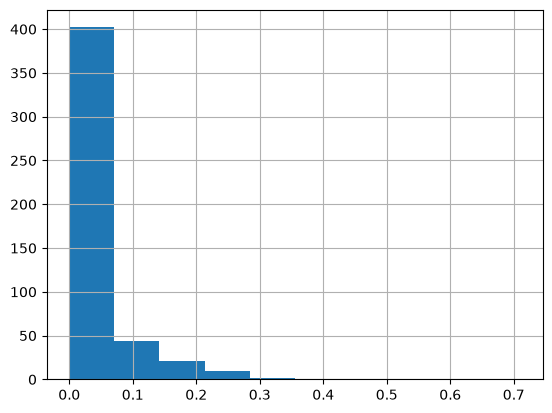

In [186]:
df_voisin0.distance.hist()

In [187]:
G = nx.from_pandas_edgelist(df_voisin, 'term_x', 'term_y', ['distance'])
nodes = df_voisin[["term_x"]].rename(columns={"term_x":"q45_clé"}).drop_duplicates().merge(df01[["q45_clé","labo","ufr","departement","ecole_doc","q11_quali_or_quanti","label_recherche_1"]], on=["q45_clé"], how="left")
nodes

,q45_clé,labo,ufr,departement,ecole_doc,q11_quali_or_quanti,label_recherche_1
0,639H-EH8R,NaN,NaN,NaN,NaN,Des données qualitatives,Recherche et création
1,9K9T-RVNL,dysco,psychologie,NaN,NaN,Des données quantitatives,Psychologie sociale
2,9X9M-JRJW,dysco,psychologie,NaN,NaN,Les deux,Psychologie
3,A33H-5ZS7,NaN,NaN,NaN,NaN,Des données quantitatives,Psychologie sociale
4,A3S4-MJGK,legs,erites,NaN,NaN,Des données qualitatives,"Sociétés, espaces et environnements"
...,...,...,...,...,...,...,...
112,TSZM-D83G,NaN,NaN,NaN,NaN,Des données qualitatives,Etudes sociales des oeuvres culturelle
113,VR4Q-ZFTH,paragraphe,NaN,NaN,cli,Des données qualitatives,Etudes sociales des oeuvres culturelle
114,X48K-M3K4,circeft,NaN,NaN,pts,Des données qualitatives,Histoires sociales du politique
115,XGV3-TLNC,cresppa,iee,NaN,NaN,Des données qualitatives,Etudes sociales des oeuvres culturelle


In [188]:
#first compute the best partition
partition_1 = nx.community.louvain_communities(G, seed=111, resolution=1)
partition_2 = nx.community.louvain_communities(G, seed=111, resolution=2)
len(partition_2)

11

In [189]:
dict_partition_1 = {}
dict_partition_2 = {}

for n, part in enumerate(partition_1):
    for key in part:
        dict_partition_1[key] = n


for n, part in enumerate(partition_2):
    for key in part:
        dict_partition_2[key] = n

nodes["Label"] = nodes.q45_clé
nodes["partition_1"]= nodes.q45_clé.map(dict_partition_1.get)
nodes["partition_2"]= nodes.q45_clé.map(dict_partition_2.get)
node_attr = nodes.set_index('q45_clé').to_dict('index')
nx.set_node_attributes(G, node_attr)


In [190]:
Sigma(G, node_size = G.degree, node_color = partition_2)

Sigma(nx.Graph with 117 nodes and 340 edges)

In [191]:
Sigma(G, node_size = G.degree, node_color = "label_recherche_1")

Sigma(nx.Graph with 117 nodes and 340 edges)

In [192]:
df = pd.read_csv("../script_traitement/buparis8_chercheurs_besoins_accompagnement_7-24-2026_9_54.csv", sep =";")
df[["146. Clé", "143. Prénom", "142. Nom"]].loc[df["146. Clé"]=="2Y89-7BR9"]

,146. Clé,143. Prénom,142. Nom
105,2Y89-7BR9,Claire,Larsonneur


In [193]:
for x in df["109. research_fields"].loc[df["142. Nom"].isin(["Rieucau"])]:
    print(x)

SH1 Individus, marchés et organisations;SH5 Textes et concepts


In [194]:
df_rf.loc[df_rf.q45_clé=="82N2-HDNU"]

,q45_clé,q24_research_fields,q24_research_domain,value
107,82N2-HDNU,"SH1 Individus, marchés et organisations",Sciences sociales et humaines,1
107,82N2-HDNU,SH5 Textes et concepts,Sciences sociales et humaines,1


## Labellisation "automatique" basée sur une forme e TF-IDF

$\text{TFIDF} = \text{TF} \times \text{IDF}$


$\text{TF} = \frac{\text{number of time term T appears in document D}}{\text{Total numbers of terms in document d}}$


$\text{IDF} = \frac{\text{Total number of documents D in corpus}}{\text{Numbers of documents containing term T}}$

$\text{TF} = \frac{\text{nOmbre de fois que le champ F de recherche apparaît dans le cluster C}}{\text{Nombre total de champs dans le cluster C}}$


$\text{IDF} = \frac{\text{Nombre total de cluster}}{\text{Nombre de cluster contenant le champ F}}$

In [195]:
df_rf["cluster"] = df_rf.q45_clé.map(dict_partition_1)
dict_spec_fields = {}
i=-1
for c in df_rf.cluster.unique():
    i+=1
    cl = df_rf.loc[df_rf.cluster==c]
    #print("####\n", len(cl))
    list_field_cluster = []
    for field in cl.q24_research_fields.unique():
        champ_in_cl = len(cl.loc[cl.q24_research_fields==field])
        
        cl_with_field = df_rf.loc[df_rf.q24_research_fields==field].cluster.nunique()
        tf = champ_in_cl/len(cl)
        idf= np.log(df_rf.cluster.nunique()/cl_with_field)
        list_field_cluster.append({"cluster":c, "q24_research_fields":field,"tf_idf":tf*idf})
    df_f0 = pd.DataFrame.from_dict(list_field_cluster).sort_values("tf_idf", ascending=False)
    dict_spec_fields[c] = [research_fields for research_fields in df_f0.q24_research_fields.head(3)]
    
    if i ==0:
        df_f = df_f0.copy()
    else:
        df_f = pd.concat([df_f, df_f0])



In [218]:
no_cluster=6
no= nodes.loc[nodes.partition_1==no_cluster].merge(df[["146. Clé", "143. Prénom", "142. Nom"]].rename(columns={"146. Clé":"q45_clé"}), on=["q45_clé"], how="left")

dict_rf = {}
for key in no.q45_clé:
    rf = df_rf.loc[df_rf.q45_clé==key]
    #print(key)
    list_rf = []
    for x in rf.q24_research_fields:
        #print(x)
        x_split = x.split(" ")[0]
        #print(x_split)
        list_rf.append(x_split)
    dict_rf[key]=list_rf

print(dict_spec_fields[no_cluster])
no["research_fields"] = no.q45_clé.map(dict_rf.get)
no["labels"] = no.partition_1.map(dict_spec_fields.get)
no

['SH2 Institutions, gouvernance et systèmes juridiques', 'SH1 Individus, marchés et organisations', 'SH7 Mobilité humaine, environnement et espace']


,q45_clé,labo,ufr,departement,ecole_doc,q11_quali_or_quanti,label_recherche_1,Label,partition_1,partition_2,143. Prénom,142. Nom,research_fields,labels
0,AVQG-73T4,crjp8,droit,NaN,NaN,Des données qualitatives,"Individus, normes, société",AVQG-73T4,6,8,Isabelle,TA,"[SH1, SH2, SH3]","[SH2 Institutions, gouvernance et systèmes jur..."
1,HRZG-6JGE,ladyss,erites,géographie,NaN,Les deux,"Individus, normes, société",HRZG-6JGE,6,8,Segolene,Darly,"[SH1, SH2, SH3, SH7]","[SH2 Institutions, gouvernance et systèmes jur..."
2,Q5AZ-855W,NaN,NaN,NaN,NaN,Des données qualitatives,"Individus, normes, société",Q5AZ-855W,6,8,NaN,NaN,"[SH1, SH3]","[SH2 Institutions, gouvernance et systèmes jur..."
3,RXPG-46ZW,NaN,NaN,NaN,NaN,Des données qualitatives,"Individus, normes, société",RXPG-46ZW,6,8,NaN,NaN,"[SH2, SH3, SH7]","[SH2 Institutions, gouvernance et systèmes jur..."
4,SYWH-2Y8T,ladyss,erites,NaN,NaN,Des données qualitatives,"Individus, normes, société",SYWH-2Y8T,6,8,Selin,Le Visage,"[SH2, SH3, SH7]","[SH2 Institutions, gouvernance et systèmes jur..."
5,WAR9-LFJP,liage,sepf,sciences de l'education,NaN,Des données qualitatives,"Individus, normes, société",WAR9-LFJP,6,8,Laura,Odasso,"[SH2, SH3, SH7]","[SH2 Institutions, gouvernance et systèmes jur..."
6,2QNC-8AAQ,NaN,NaN,NaN,NaN,Des données qualitatives,"Individus, normes, société",2QNC-8AAQ,6,8,NaN,NaN,"[SH1, SH3, SH5, SH7]","[SH2 Institutions, gouvernance et systèmes jur..."
7,4FYP-H9TX,led,aes economie gestion,NaN,NaN,Les deux,"Individus, normes, société",4FYP-H9TX,6,8,Santiago,NUNEZ-REGUEIRO,"[SH1, SH2, SH3]","[SH2 Institutions, gouvernance et systèmes jur..."
8,5FJS-YCLW,cresppa,textes et sociétés,NaN,NaN,Des données qualitatives,"Individus, normes, société",5FJS-YCLW,6,8,Yasmine,Siblot,"[SH1, SH2, SH3, SH7]","[SH2 Institutions, gouvernance et systèmes jur..."
9,78P8-N4BA,NaN,NaN,NaN,NaN,Des données qualitatives,"Individus, normes, société",78P8-N4BA,6,8,NaN,NaN,"[SH1, SH2, SH3, SH6, SH7]","[SH2 Institutions, gouvernance et systèmes jur..."


In [208]:
no[["research_fields"]]


,research_fields
0,"[SH3, SH4]"
1,"[SH3, SH4]"
2,"[SH3, SH4]"
3,"[SH3, SH4]"
4,"[SH3, SH4]"
5,"[SH3, SH4]"


In [133]:
dict_label_part_1 = {
    0:"Psychologie",
    1: "Etudes sociales des oeuvres culturelle",
    2: "Sciences info. com.",
    3: "Sciences informatiques",
    4: "Histoires de l'art et des sciences",
    5:"Recherche et création",
    6:"Individus, normes, société",
    7: "Histoires sociales du politique",
    8: "Psychologie sociale",
    9: "Sociétés, espaces et environnements"
}

In [134]:
dict_rf = {}
for key in nodes.q45_clé:
    rf = df_rf.loc[df_rf.q45_clé==key]
    #print(key)
    list_rf = []
    for x in rf.q24_research_fields:
        #print(x)
        x_split = x.split(" ")[0]
        #print(x_split)
        list_rf.append(x_split)
    dict_rf[key]=list_rf

In [135]:
nodes["label_recherche_1"] = nodes.partition_1.map(dict_label_part_1.get)
nodes["auto_lab_research_cluster"] = nodes.partition_1.map(dict_spec_fields.get)
nodes["research_fields"] = nodes.q45_clé.map(dict_rf.get)

In [136]:
nodes.columns

Index(['q45_clé', 'labo', 'ufr', 'departement', 'ecole_doc',
       'q11_quali_or_quanti', 'label_recherche_1', 'Label', 'partition_1',
       'partition_2', 'auto_lab_research_cluster', 'research_fields'],
      dtype='object')

In [138]:
df0["label_recherche_1"] = df0.q45_clé.map(dict(zip(nodes.q45_clé, nodes.label_recherche_1)).get) 
df0["auto_lab_research_cluster"] = df0.q45_clé.map(dict(zip(nodes.q45_clé, nodes.auto_lab_research_cluster)).get) 
df0["research_fields"] = df0.q45_clé.map(dict_rf.get)
df0

,qno_obs,q1_so_principles,q2_hal_depot,q3_octavi_depot,q4_diff_data,q4_autres_entrepots,q5_r,q5_python,q5_excel,q5_julia,...,partition_1,label_recherche_1,auto_lab_research_cluster,research_fields,clust_type_data,auto_clust_data,label_clust_metho_data_kneig_4,auto_metho_data_kneig_4,label_clust_metho_data_kneig_5,auto_metho_data_kneig_5
0,1,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,NaN,None,None,None,Données textuelles et observations,"['Données textuelles ou documentaires', ""Donné...",NaN,NaN,NaN,NaN
1,2,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,4.0,Etudes sociales des oeuvres culturelle,"[SH4 L'esprit humain et sa complexité, SH8 Étu...","[SH3, SH4, SH5, SH6]",Corpus textuels,"['Données textuelles ou documentaires', 'Métad...",Méthodes mixtes,"excel, Métadonnées, Données statistiques",Collecte et analyse de traces numériques,"Données statistiques, python, Données du web"
2,3,"Oui, tout à fait","Oui, plusieurs fois",Je ne connais pas Octaviana,Non,NaN,Non,Non,Oui,Non,...,5.0,Psychologie,"[SH4 L'esprit humain et sa complexité, LS5 Neu...",[SH4],Entretiens,"['Données textuelles ou documentaires', 'Autre...",Enquêtes qualitatives et entretien,"Données textuelles ou documentaires, Données d...",Enquête par entretien,"Données textuelles ou documentaires, excel, Do..."
3,4,"Oui, un peu","Oui, une fois",Non,"Autre, précisez",OSF,Oui,Non,Non,Non,...,5.0,Psychologie,"[SH4 L'esprit humain et sa complexité, LS5 Neu...",[SH4],Etudes expérimentale,"[""Données expérimentales ou d'observation"", ""D...",Analyse de données expérimentales,"Données statistiques, Données expérimentales o...",Approches expérimentales,"Données statistiques, r, excel"
4,5,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Non,Non,Oui,Non,...,3.0,Histoires sociales du politique,"[SH8 Études des cultures et des arts, SH6 L'ét...","[SH1, SH3, SH6, SH8]",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Méthodes mixtes,"excel, Métadonnées, Données statistiques",Enquête par entretien,"Données textuelles ou documentaires, excel, Do..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,117,"Oui, un peu","Oui, plusieurs fois",Non,"Autre, précisez",OSF,Oui,Oui,Oui,Non,...,5.0,Psychologie,"[SH4 L'esprit humain et sa complexité, LS5 Neu...","[SH4, LS5]",Données statistiques et observations,"['Données statistiques', ""Données expérimental...",Approches expérimentales/cliniques,"Données expérimentales ou d'observation, excel, r",Approches expérimentales,"Données statistiques, r, excel"
115,118,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Oui,Non,Oui,Non,...,0.0,"Individus, normes, société","[SH2 Institutions, gouvernance et systèmes jur...","[SH2, SH3, SH7]",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do..."
116,119,"Oui, un peu","Oui, plusieurs fois",Non,Non,NaN,Oui,Non,Oui,Non,...,0.0,"Individus, normes, société","[SH2 Institutions, gouvernance et systèmes jur...","[SH1, SH2, SH3, SH7]",Données statistiques et textutelles,"['Données statistiques', 'Données textuelles o...",Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do..."
117,120,Non,"Oui, plusieurs fois",Non;Je ne connais pas Octaviana,"Autre, précisez",Mendeley data,Non,Oui,Oui,Non,...,10.0,Sciences informatiques,"[PE6 Sciences informatiques et informatique, P...","[PE1, PE6, PE8, PE11]",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Collectes et analyses de traces numériques,"Données du web, Données multimédia, Données st...",Collecte et analyse de traces numériques,"Données statistiques, python, Données du web"


In [71]:
#df02 = df0.loc[~df0.q45_clé.isin(["Z37Y-6JGC","QNYZ-3MH2"])].merge(nodes[['q45_clé', 'labo', 'ufr', 'departement', 'ecole_doc',
       'partition_1', 'label_recherche_1','auto_lab_research_cluster', 'research_fields']], on =["q45_clé"], how="left")


,qno_obs,q1_so_principles,q2_hal_depot,q3_octavi_depot,q4_diff_data,q4_autres_entrepots,q5_r,q5_python,q5_excel,q5_julia,...,q26_1_autre_rec,q35_ia_tools_rec,labo,ufr,departement,ecole_doc,partition_1,label_recherche_1,auto_lab_research_cluster,research_fields
0,1,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,NaN,NaN,NaN,NaN,NaN,NaN,4.0,Etudes sociales des arts et de la culture,"[SH4 L'esprit humain et sa complexité, SH8 Étu...","[SH3, SH4, SH5, SH6]"
2,3,"Oui, tout à fait","Oui, plusieurs fois",Je ne connais pas Octaviana,Non,NaN,Non,Non,Oui,Non,...,NaN,chatgpt|mistral|notebooklm,paragraphe,psychologie,NaN,NaN,5.0,Psychologie,"[SH4 L'esprit humain et sa complexité, LS5 Neu...",[SH4]
3,4,"Oui, un peu","Oui, une fois",Non,"Autre, précisez",OSF,Oui,Non,Non,Non,...,NaN,chatgpt|euria,sfl,sdl,NaN,NaN,5.0,Psychologie,"[SH4 L'esprit humain et sa complexité, LS5 Neu...",[SH4]
4,5,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Non,Non,Oui,Non,...,NaN,NaN,NaN,NaN,NaN,NaN,3.0,Histoires de l'art et des sciences,"[SH8 Études des cultures et des arts, SH6 L'ét...","[SH1, SH3, SH6, SH8]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,117,"Oui, un peu","Oui, plusieurs fois",Non,"Autre, précisez",OSF,Oui,Oui,Oui,Non,...,NaN,NaN,dysco,NaN,NaN,NaN,5.0,Psychologie,"[SH4 L'esprit humain et sa complexité, LS5 Neu...","[SH4, LS5]"
115,118,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Oui,Non,Oui,Non,...,Bibliothèque|Où je peux,claude|chatgpt,liage,sepf,sciences de l'education,NaN,0.0,"Individus, normes, sociétés","[SH2 Institutions, gouvernance et systèmes jur...","[SH2, SH3, SH7]"
116,119,"Oui, un peu","Oui, plusieurs fois",Non,Non,NaN,Oui,Non,Oui,Non,...,NaN,NaN,ladyss,erites,géographie,NaN,0.0,"Individus, normes, sociétés","[SH2 Institutions, gouvernance et systèmes jur...","[SH1, SH2, SH3, SH7]"
117,120,Non,"Oui, plusieurs fois",Non;Je ne connais pas Octaviana,"Autre, précisez",Mendeley data,Non,Oui,Oui,Non,...,NaN,correcteurs d'orthographe,NaN,NaN,NaN,NaN,10.0,Sciences informatiques,"[PE6 Sciences informatiques et informatique, P...","[PE1, PE6, PE8, PE11]"


In [141]:
print(df0.label_recherche_1.value_counts().to_markdown())

| label_recherche_1                      |   count |
|:---------------------------------------|--------:|
| Etudes sociales des oeuvres culturelle |      19 |
| Psychologie                            |      18 |
| Individus, normes, société             |      16 |
| Histoires de l'art et des sciences     |      13 |
| Histoires sociales du politique        |      11 |
| Sciences info. com.                    |      10 |
| Recherche et création                  |       9 |
| Sociétés, espaces et environnements    |       8 |
| Sciences informatiques                 |       7 |
| Psychologie sociale                    |       6 |


In [139]:
# on enregistre les nouvelles variables dans le dataframe original
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "w") as file_out:
    df0.to_csv(file_out, sep=",", index= False)

In [45]:
dic_new_var = {'name':"Aire de rechere",
               'label':'label_recherche_1',
               'group':'champ de recherche',
               'personal_data':False,
               'type':'simple_nominal',
               'opened_question':False,
               'type_panda':df02.label_recherche_1.dtypes,
               'no_question':109,
               'question':"",
               'question_family':'',
               'comment':"Label donnés manuellement aux clusters des champs de recherche"
              }
new_variable = pd.DataFrame.from_dict(data=[dic_new_var])
new_variable
df_col1 = pd.concat([df_col,new_variable], ignore_index = True)
df_col1

,name,label,group,personal_data,type,opened_question,type_panda,no_question,question,question_family,comment
0,N°Obs,qno_obs,NaN,False,numérique,False,int64,0.0,NaN,qno,NaN
1,1. so_principles,q1_so_principles,1_connaissance_so,False,ordinal,False,object,1.0,1/ Diriez-vous que vous êtes familier.ère des ...,q1,NaN
2,2. hal_depot,q2_hal_depot,1_connaissance_so,False,ordinal,False,object,2.0,2/ Avez-vous déjà déposé une production scient...,q2,NaN
3,3. octavi_depot,q3_octavi_depot,2_bib_num,False,nominal_multiple,False,object,3.0,3/ Avez-vous des productions déposées sur Octa...,q3,NaN
4,4. open_data,q4_diff_data,3_entrepot,False,nominal_multiple,False,object,4.0,4/ Avez-vous déjà diffusé vos données de reche...,q4,NaN
...,...,...,...,...,...,...,...,...,...,...,...
153,16. recodage dev_exemple groupe,q6_1_dev_group,5_developpement,False,simple_nominal,False,object,16.0,"6.1/ Si oui, pourriez-vous expliquer ce que vo...",NaN,Classe les exemples de logiciels développés da...
154,16. recodage dev_exemple how,q6_1_dev_how,5_developpement,False,simple_nominal,False,object,16.0,"6.1/ Si oui, pourriez-vous expliquer ce que vo...",NaN,Précise le langage ou l'outil de programmation...
155,"113. recodage Autre, précisez",q26_1_autre_rec,13_env_travail,False,nominal_multiple,False,object,113.0,"Où travaillez-vous le plus souvent? Si autre, ...",q26,recode les autre lieux
156,135. recodage ia_tools,q35_ia_tools,4_logiciel_traitement,False,nominal_multiple,False,object,135.0,"Si oui, lesquels ?",q35,recode les outils ia


In [72]:
dic_new_var = {'name':"Labellisation automatique des clusters de recherche",
               'label':'auto_lab_research_cluster',
               'group':'champ de recherche',
               'personal_data':False,
               'type':'simple_nominal',
               'opened_question':False,
               'type_panda':df02.auto_lab_research_cluster.dtypes,
               'no_question':109,
               'question':"",
               'question_family':'',
               'comment':"Label donnés automatiques aux clusters des champs de recherche sur la base d'un TF-IDF (champ de recherche le plus spécifiques à chaque cluster)"
              }
new_variable = pd.DataFrame.from_dict(data=[dic_new_var])
new_variable
df_col2 = pd.concat([df_col1,new_variable], ignore_index = True)
df_col2

dic_new_var = {'name':"Champ de recherche",
               'label':'research_fields',
               'group':'champ de recherche',
               'personal_data':False,
               'type':'simple_nominal',
               'opened_question':False,
               'type_panda':df02.research_fields.dtypes,
               'no_question':109,
               'question':"",
               'question_family':'',
               'comment':"liste des champs de recherche sélectionné avec seulement l'abréviation(SH1, LS1, etc.)"
              }
new_variable = pd.DataFrame.from_dict(data=[dic_new_var])
new_variable
df_col3 = pd.concat([df_col2,new_variable], ignore_index = True)
df_col3

,name,label,group,personal_data,type,opened_question,type_panda,no_question,question,question_family,comment
0,N°Obs,qno_obs,NaN,False,numérique,False,int64,0.0,NaN,qno,NaN
1,1. so_principles,q1_so_principles,1_connaissance_so,False,ordinal,False,object,1.0,1/ Diriez-vous que vous êtes familier.ère des ...,q1,NaN
2,2. hal_depot,q2_hal_depot,1_connaissance_so,False,ordinal,False,object,2.0,2/ Avez-vous déjà déposé une production scient...,q2,NaN
3,3. octavi_depot,q3_octavi_depot,2_bib_num,False,nominal_multiple,False,object,3.0,3/ Avez-vous des productions déposées sur Octa...,q3,NaN
4,4. open_data,q4_diff_data,3_entrepot,False,nominal_multiple,False,object,4.0,4/ Avez-vous déjà diffusé vos données de reche...,q4,NaN
...,...,...,...,...,...,...,...,...,...,...,...
155,"113. recodage Autre, précisez",q26_1_autre_rec,13_env_travail,False,nominal_multiple,False,object,113.0,"Où travaillez-vous le plus souvent? Si autre, ...",q26,recode les autre lieux
156,135. recodage ia_tools,q35_ia_tools,4_logiciel_traitement,False,nominal_multiple,False,object,135.0,"Si oui, lesquels ?",q35,recode les outils ia
157,Aire de rechere,label_recherche_1,champ de recherche,False,simple_nominal,False,object,109.0,,,Label donnés manuellement aux clusters des cha...
158,Labellisation automatique des clusters de rech...,auto_lab_research_cluster,champ de recherche,False,simple_nominal,False,object,109.0,,,Label donnés automatiques aux clusters des cha...


In [73]:
df_col3.to_csv("../le_questionnaire/dico_variable.csv", sep=",", index= False)